# PyTorch Deep Learning Model

This notebook develops a PyTorch neural network for security incident triage
using categorical embeddings and numerical features.

The model is evaluated using the same leakage-aware grouped split and
Macro-F1 metric as the classical Logistic Regression baseline.

## Imports

In [56]:
from pathlib import Path
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

## Reproducibility

In [57]:
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

## Device

In [58]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using device:", device)

Using device: cpu


## Paths

In [59]:
current_path = Path.cwd()

if current_path.name == "notebooks":
    PROJECT_ROOT = current_path.parent
else:
    PROJECT_ROOT = current_path

DATA_DIR = PROJECT_ROOT / "data" / "raw"

TRAIN_PATH = DATA_DIR / "GUIDE_Train.csv"

print("Project root:", PROJECT_ROOT)
print("Train dataset:", TRAIN_PATH)

Project root: c:\Users\zaaaa\OneDrive\Υπολογιστής\New folder\Python Projects\ai-security-incident-triage
Train dataset: c:\Users\zaaaa\OneDrive\Υπολογιστής\New folder\Python Projects\ai-security-incident-triage\data\raw\GUIDE_Train.csv


In [60]:
df = pd.read_csv(
    TRAIN_PATH,
    nrows=100_000,
    low_memory=False
)

print("Shape:", df.shape)

Shape: (100000, 45)


## Clean target

In [61]:
TARGET = "IncidentGrade"

df = df.dropna(
    subset=[TARGET]
).copy()

print("Labeled rows:", len(df))

print(
    df[TARGET]
    .value_counts(normalize=True)
    .round(3)
)

Labeled rows: 99475
IncidentGrade
BenignPositive    0.433
TruePositive      0.351
FalsePositive     0.217
Name: proportion, dtype: float64


## Group key

In [62]:
df["IncidentGroup"] = (
    df["OrgId"].astype(str)
    + "_"
    + df["IncidentId"].astype(str)
)

## Feature engineering

In [63]:
df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce",
    utc=True
)

df["Hour"] = df["Timestamp"].dt.hour

df["DayOfWeek"] = (
    df["Timestamp"].dt.dayofweek
)

df["IsWeekend"] = (
    df["DayOfWeek"] >= 5
).astype(int)

df["HasMitreTechnique"] = (
    df["MitreTechniques"]
    .notna()
    .astype(int)
)

## Feature definitions

In [64]:
categorical_features = [
    "DetectorId",
    "AlertTitle",
    "Category",
    "EntityType",
    "EvidenceRole",

    "RegistryKey",
    "RegistryValueName",
    "RegistryValueData",

    "ApplicationId",
    "ApplicationName",
    "OAuthApplicationId",

    "ResourceIdName",

    "OSFamily",
    "OSVersion",

    "CountryCode",
    "State",
    "City"
]

In [65]:
numeric_features = [
    "Hour",
    "DayOfWeek",
    "IsWeekend",
    "HasMitreTechnique"
]

In [66]:
len(categorical_features)

17

In [67]:
len(numeric_features)

4

## Split

In [68]:
X = df[
    categorical_features
    + numeric_features
].copy()

y = df[TARGET].copy()

groups = df["IncidentGroup"].copy()

In [69]:
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        X,
        y,
        groups=groups
    )
)

In [70]:
X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

groups_train = groups.iloc[train_idx]
groups_val = groups.iloc[val_idx]

## Verify

In [71]:
overlap = set(groups_train).intersection(
    set(groups_val)
)

print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Overlapping incidents:", len(overlap))

Train: 79580
Validation: 19895
Overlapping incidents: 0


## Categorical vocabulary and encoding

In [72]:
MISSING_TOKEN = "__MISSING__"
UNKNOWN_INDEX = 0

category_maps = {}

X_train_cat = pd.DataFrame(
    index=X_train.index
)

X_val_cat = pd.DataFrame(
    index=X_val.index
)

In [73]:
for column in categorical_features:

    train_values = (
        X_train[column]
        .fillna(MISSING_TOKEN)
        .astype(str)
    )

    val_values = (
        X_val[column]
        .fillna(MISSING_TOKEN)
        .astype(str)
    )

    unique_train_values = sorted(
        train_values.unique()
    )

    mapping = {
        value: index + 1
        for index, value
        in enumerate(unique_train_values)
    }

    category_maps[column] = mapping

    X_train_cat[column] = (
        train_values
        .map(mapping)
        .astype(np.int64)
    )

    X_val_cat[column] = (
        val_values
        .map(mapping)
        .fillna(UNKNOWN_INDEX)
        .astype(np.int64)
    )

In [74]:
X_train_cat.head()

,DetectorId,AlertTitle,Category,EntityType,EvidenceRole,RegistryKey,RegistryValueName,RegistryValueData,ApplicationId,ApplicationName,OAuthApplicationId,ResourceIdName,OSFamily,OSVersion,CountryCode,State,City
1,1600,5719,8,24,1,12,25,34,30,59,14,42,4,12,32,57,25
2,1354,4102,11,23,2,12,25,34,30,59,14,42,4,12,32,57,25
3,658,2500,2,23,2,12,25,34,30,59,14,42,4,12,32,57,25
4,1980,8156,7,24,1,12,25,34,30,59,14,42,4,12,32,57,25
5,1,1,11,11,2,12,25,34,30,59,14,42,4,12,92,281,338


In [75]:
category_cardinalities = {
    column: len(category_maps[column]) + 1
    for column in categorical_features
}

for column, cardinality in category_cardinalities.items():
    print(
        f"{column:25s} -> {cardinality}"
    )

DetectorId                -> 2072
AlertTitle                -> 9449
Category                  -> 19
EntityType                -> 25
EvidenceRole              -> 3
RegistryKey               -> 48
RegistryValueName         -> 30
RegistryValueData         -> 39
ApplicationId             -> 73
ApplicationName           -> 104
OAuthApplicationId        -> 15
ResourceIdName            -> 62
OSFamily                  -> 5
OSVersion                 -> 15
CountryCode               -> 104
State                     -> 345
City                      -> 743


In [76]:
print("Unknown categories in validation:\n")

for column in categorical_features:

    unknown_count = (
        X_val_cat[column] == UNKNOWN_INDEX
    ).sum()

    print(
        f"{column:25s} -> {unknown_count}"
    )

Unknown categories in validation:

DetectorId                -> 478
AlertTitle                -> 2601
Category                  -> 0
EntityType                -> 1
EvidenceRole              -> 0
RegistryKey               -> 19
RegistryValueName         -> 5
RegistryValueData         -> 8
ApplicationId             -> 13
ApplicationName           -> 20
OAuthApplicationId        -> 4
ResourceIdName            -> 13
OSFamily                  -> 0
OSVersion                 -> 0
CountryCode               -> 2
State                     -> 28
City                      -> 112


## Numerical preprocessing

In [77]:
X_train_num = (
    X_train[numeric_features]
    .copy()
    .astype(float)
)

X_val_num = (
    X_val[numeric_features]
    .copy()
    .astype(float)
)

## Missing numerical values

In [78]:
numeric_medians = (
    X_train_num
    .median()
)

X_train_num = (
    X_train_num
    .fillna(numeric_medians)
)

X_val_num = (
    X_val_num
    .fillna(numeric_medians)
)

## StandardScaler

In [79]:
scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(
    X_train_num
)

X_val_num_scaled = scaler.transform(
    X_val_num
)

## Convert to float32

In [80]:
X_train_num_scaled = (
    X_train_num_scaled
    .astype(np.float32)
)

X_val_num_scaled = (
    X_val_num_scaled
    .astype(np.float32)
)

## Target encoding

In [81]:
label_to_index = {
    "BenignPositive": 0,
    "FalsePositive": 1,
    "TruePositive": 2
}

index_to_label = {
    index: label
    for label, index
    in label_to_index.items()
}

In [82]:
y_train_encoded = (
    y_train
    .map(label_to_index)
    .to_numpy(dtype=np.int64)
)

y_val_encoded = (
    y_val
    .map(label_to_index)
    .to_numpy(dtype=np.int64)
)

In [83]:
print(
    "Train labels:",
    np.unique(
        y_train_encoded,
        return_counts=True
    )
)

print(
    "Validation labels:",
    np.unique(
        y_val_encoded,
        return_counts=True
    )
)

Train labels: (array([0, 1, 2]), array([34419, 17251, 27910]))
Validation labels: (array([0, 1, 2]), array([8605, 4313, 6977]))


## PyTorch Dataset

In [84]:
class SecurityIncidentDataset(Dataset):

    def __init__(
        self,
        categorical_data,
        numerical_data,
        labels
    ):

        self.categorical_data = torch.tensor(
            categorical_data,
            dtype=torch.long
        )

        self.numerical_data = torch.tensor(
            numerical_data,
            dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        return (
            self.categorical_data[index],
            self.numerical_data[index],
            self.labels[index]
        )

## Creating Dataset objects

In [85]:
X_train_cat_array = (
    X_train_cat
    .to_numpy(dtype=np.int64)
)

X_val_cat_array = (
    X_val_cat
    .to_numpy(dtype=np.int64)
)

In [86]:
train_dataset = SecurityIncidentDataset(
    X_train_cat_array,
    X_train_num_scaled,
    y_train_encoded
)

val_dataset = SecurityIncidentDataset(
    X_val_cat_array,
    X_val_num_scaled,
    y_val_encoded
)

In [87]:
print(
    "Train dataset:",
    len(train_dataset)
)

print(
    "Validation dataset:",
    len(val_dataset)
)

Train dataset: 79580
Validation dataset: 19895


## Example

In [88]:
categorical_example, numerical_example, label_example = (
    train_dataset[0]
)

print(
    "Categorical shape:",
    categorical_example.shape
)

print(
    "Numerical shape:",
    numerical_example.shape
)

print(
    "Label:",
    label_example
)

Categorical shape: torch.Size([17])
Numerical shape: torch.Size([4])
Label: tensor(1)


## DataLoaders

In [89]:
BATCH_SIZE = 256

generator = torch.Generator()
generator.manual_seed(RANDOM_SEED)

In [90]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

## First Batch

In [91]:
cat_batch, num_batch, label_batch = next(
    iter(train_loader)
)

print(
    "Categorical batch:",
    cat_batch.shape,
    cat_batch.dtype
)

print(
    "Numerical batch:",
    num_batch.shape,
    num_batch.dtype
)

print(
    "Labels batch:",
    label_batch.shape,
    label_batch.dtype
)

Categorical batch: torch.Size([256, 17]) torch.int64
Numerical batch: torch.Size([256, 4]) torch.float32
Labels batch: torch.Size([256]) torch.int64


## Embedding dimensions

In [92]:
def choose_embedding_dim(cardinality):
    if cardinality <= 4:
        return 2
    elif cardinality <= 16:
        return 4
    elif cardinality <= 64:
        return 8
    elif cardinality <= 256:
        return 16
    else:
        return 32

In [93]:
embedding_dims = {
    column: choose_embedding_dim(
        category_cardinalities[column]
    )
    for column in categorical_features
}

In [94]:
for column in categorical_features:
    print(
        f"{column:25s} "
        f"cardinality={category_cardinalities[column]:5d} "
        f"embedding_dim={embedding_dims[column]:2d}"
    )

DetectorId                cardinality= 2072 embedding_dim=32
AlertTitle                cardinality= 9449 embedding_dim=32
Category                  cardinality=   19 embedding_dim= 8
EntityType                cardinality=   25 embedding_dim= 8
EvidenceRole              cardinality=    3 embedding_dim= 2
RegistryKey               cardinality=   48 embedding_dim= 8
RegistryValueName         cardinality=   30 embedding_dim= 8
RegistryValueData         cardinality=   39 embedding_dim= 8
ApplicationId             cardinality=   73 embedding_dim=16
ApplicationName           cardinality=  104 embedding_dim=16
OAuthApplicationId        cardinality=   15 embedding_dim= 4
ResourceIdName            cardinality=   62 embedding_dim= 8
OSFamily                  cardinality=    5 embedding_dim= 4
OSVersion                 cardinality=   15 embedding_dim= 4
CountryCode               cardinality=  104 embedding_dim=16
State                     cardinality=  345 embedding_dim=32
City                    

## Size of embedded input

In [95]:
total_embedding_dim = sum(
    embedding_dims.values()
)

print(
    "Total embedding dimensions:",
    total_embedding_dim
)

print(
    "Numerical dimensions:",
    len(numeric_features)
)

print(
    "Total neural-network input:",
    total_embedding_dim
    + len(numeric_features)
)

Total embedding dimensions: 238
Numerical dimensions: 4
Total neural-network input: 242


## Neural network architecture

In [96]:
class IncidentTriageNetwork(nn.Module):

    def __init__(
        self,
        categorical_features,
        category_cardinalities,
        embedding_dims,
        num_numeric_features,
        num_classes=3
    ):
        super().__init__()

        self.categorical_features = categorical_features

        self.embeddings = nn.ModuleList([
            nn.Embedding(
                num_embeddings=category_cardinalities[column],
                embedding_dim=embedding_dims[column]
            )
            for column in categorical_features
        ])

        total_embedding_dim = sum(
            embedding_dims[column]
            for column in categorical_features
        )

        total_input_dim = (
            total_embedding_dim
            + num_numeric_features
        )

        self.network = nn.Sequential(
            nn.Linear(total_input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(64, num_classes)
        )


    def forward(
        self,
        categorical_data,
        numerical_data
    ):

        embedded_features = []

        for i, embedding_layer in enumerate(
            self.embeddings
        ):
            embedded = embedding_layer(
                categorical_data[:, i]
            )

            embedded_features.append(
                embedded
            )

        categorical_embeddings = torch.cat(
            embedded_features,
            dim=1
        )

        combined_features = torch.cat(
            [
                categorical_embeddings,
                numerical_data
            ],
            dim=1
        )

        logits = self.network(
            combined_features
        )

        return logits

## Create model

In [97]:
model = IncidentTriageNetwork(
    categorical_features=categorical_features,
    category_cardinalities=category_cardinalities,
    embedding_dims=embedding_dims,
    num_numeric_features=len(numeric_features),
    num_classes=3
)

model = model.to(device)

In [98]:
print(model)

IncidentTriageNetwork(
  (embeddings): ModuleList(
    (0): Embedding(2072, 32)
    (1): Embedding(9449, 32)
    (2): Embedding(19, 8)
    (3): Embedding(25, 8)
    (4): Embedding(3, 2)
    (5): Embedding(48, 8)
    (6): Embedding(30, 8)
    (7): Embedding(39, 8)
    (8): Embedding(73, 16)
    (9): Embedding(104, 16)
    (10): Embedding(15, 4)
    (11): Embedding(62, 8)
    (12): Embedding(5, 4)
    (13): Embedding(15, 4)
    (14): Embedding(104, 16)
    (15): Embedding(345, 32)
    (16): Embedding(743, 32)
  )
  (network): Sequential(
    (0): Linear(in_features=242, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)


## Trainable parameters

In [99]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(
    "Total parameters:",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)

Total parameters: 449,469
Trainable parameters: 449,469


## First Forward Pass

In [100]:
cat_batch = cat_batch.to(device)
num_batch = num_batch.to(device)
label_batch = label_batch.to(device)

In [101]:
model.eval()

with torch.no_grad():

    logits = model(
        cat_batch,
        num_batch
    )

print(
    "Logits shape:",
    logits.shape
)

Logits shape: torch.Size([256, 3])


In [102]:
print(
    logits[:5]
)

tensor([[-0.0715, -0.0557, -0.1261],
        [-0.0189,  0.0053, -0.1224],
        [ 0.0059, -0.0042, -0.1388],
        [-0.0703,  0.0501, -0.0525],
        [-0.0813,  0.0239, -0.0020]])


## Logits to probabilities

In [103]:
probabilities = torch.softmax(
    logits,
    dim=1
)

print(
    probabilities[:5]
)

tensor([[0.3375, 0.3429, 0.3196],
        [0.3417, 0.3501, 0.3081],
        [0.3502, 0.3467, 0.3031],
        [0.3179, 0.3585, 0.3236],
        [0.3132, 0.3479, 0.3390]])


In [104]:
print(
    probabilities[:5].sum(dim=1)
)

tensor([1., 1., 1., 1., 1.])


In [105]:
predicted_classes = torch.argmax(
    logits,
    dim=1
)

print(
    predicted_classes[:10]
)

print(
    label_batch[:10]
)

tensor([1, 1, 0, 1, 1, 1, 1, 1, 1, 2])
tensor([0, 0, 0, 2, 1, 1, 0, 2, 0, 0])


## Loss function and class weights

In [106]:
class_counts = np.bincount(
    y_train_encoded
)

class_weights = (
    len(y_train_encoded)
    / (
        len(class_counts)
        * class_counts
    )
)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

Class counts: [34419 17251 27910]
Class weights: [0.77069835 1.53768864 0.95043592]


In [107]:
class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

In [108]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

## Optimizer

In [109]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

## Training and validation functions

In [110]:
def train_one_epoch(
    model,
    data_loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    for (
        categorical_batch,
        numerical_batch,
        labels_batch
    ) in data_loader:

        categorical_batch = (
            categorical_batch.to(device)
        )

        numerical_batch = (
            numerical_batch.to(device)
        )

        labels_batch = (
            labels_batch.to(device)
        )

        optimizer.zero_grad()

        logits = model(
            categorical_batch,
            numerical_batch
        )

        loss = criterion(
            logits,
            labels_batch
        )

        loss.backward()

        optimizer.step()

        batch_size = labels_batch.size(0)

        running_loss += (
            loss.item()
            * batch_size
        )

        total_samples += batch_size

    average_loss = (
        running_loss
        / total_samples
    )

    return average_loss

## Validation function

In [111]:
def evaluate_model(
    model,
    data_loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():

        for (
            categorical_batch,
            numerical_batch,
            labels_batch
        ) in data_loader:

            categorical_batch = (
                categorical_batch.to(device)
            )

            numerical_batch = (
                numerical_batch.to(device)
            )

            labels_batch = (
                labels_batch.to(device)
            )

            logits = model(
                categorical_batch,
                numerical_batch
            )

            loss = criterion(
                logits,
                labels_batch
            )

            predictions = torch.argmax(
                logits,
                dim=1
            )

            batch_size = labels_batch.size(0)

            running_loss += (
                loss.item()
                * batch_size
            )

            total_samples += batch_size

            all_labels.extend(
                labels_batch
                .cpu()
                .numpy()
            )

            all_predictions.extend(
                predictions
                .cpu()
                .numpy()
            )

    average_loss = (
        running_loss
        / total_samples
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return (
        average_loss,
        macro_f1,
        np.array(all_labels),
        np.array(all_predictions)
    )

## Model training

In [112]:
NUM_EPOCHS = 25
PATIENCE = 5

best_val_f1 = -np.inf
best_model_state = None
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_f1": []
}

In [113]:
for epoch in range(
    1,
    NUM_EPOCHS + 1
):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        val_loss,
        val_f1,
        _,
        _
    ) = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    history["train_loss"].append(
        train_loss
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_f1"].append(
        val_f1
    )

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Macro-F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1

        best_model_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:

        print(
            "\nEarly stopping triggered."
        )

        break

Epoch 01 | Train Loss: 0.7638 | Val Loss: 0.7192 | Val Macro-F1: 0.6980
Epoch 02 | Train Loss: 0.6210 | Val Loss: 0.6707 | Val Macro-F1: 0.7184
Epoch 03 | Train Loss: 0.5806 | Val Loss: 0.6517 | Val Macro-F1: 0.7167
Epoch 04 | Train Loss: 0.5568 | Val Loss: 0.6477 | Val Macro-F1: 0.7255
Epoch 05 | Train Loss: 0.5395 | Val Loss: 0.6518 | Val Macro-F1: 0.7172
Epoch 06 | Train Loss: 0.5286 | Val Loss: 0.6638 | Val Macro-F1: 0.7300
Epoch 07 | Train Loss: 0.5183 | Val Loss: 0.6548 | Val Macro-F1: 0.7379
Epoch 08 | Train Loss: 0.5093 | Val Loss: 0.6757 | Val Macro-F1: 0.7395
Epoch 09 | Train Loss: 0.5005 | Val Loss: 0.6695 | Val Macro-F1: 0.7396
Epoch 10 | Train Loss: 0.4947 | Val Loss: 0.6687 | Val Macro-F1: 0.7392
Epoch 11 | Train Loss: 0.4906 | Val Loss: 0.6648 | Val Macro-F1: 0.7305
Epoch 12 | Train Loss: 0.4866 | Val Loss: 0.6780 | Val Macro-F1: 0.7355
Epoch 13 | Train Loss: 0.4800 | Val Loss: 0.6787 | Val Macro-F1: 0.7366
Epoch 14 | Train Loss: 0.4763 | Val Loss: 0.6925 | Val Macro-F1:

## Restore best model

In [114]:
model.load_state_dict(
    best_model_state
)

print(
    f"Best validation Macro-F1: "
    f"{best_val_f1:.4f}"
)

Best validation Macro-F1: 0.7455


## Plot training history

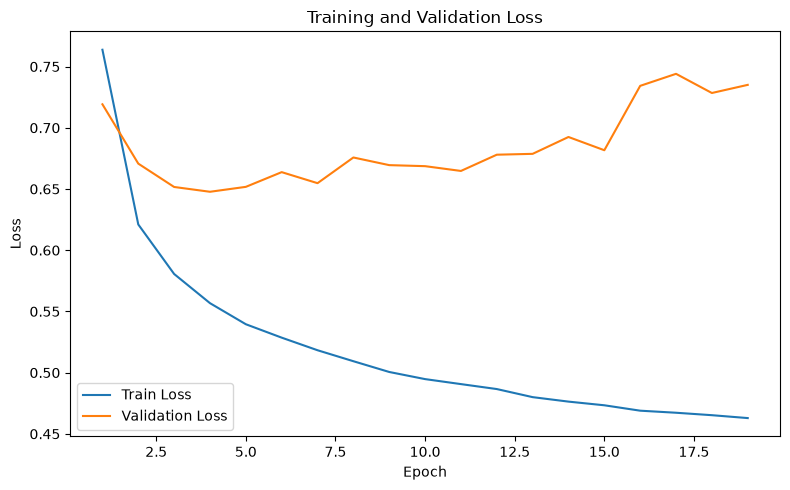

In [115]:
epochs_ran = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_ran,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs_ran,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

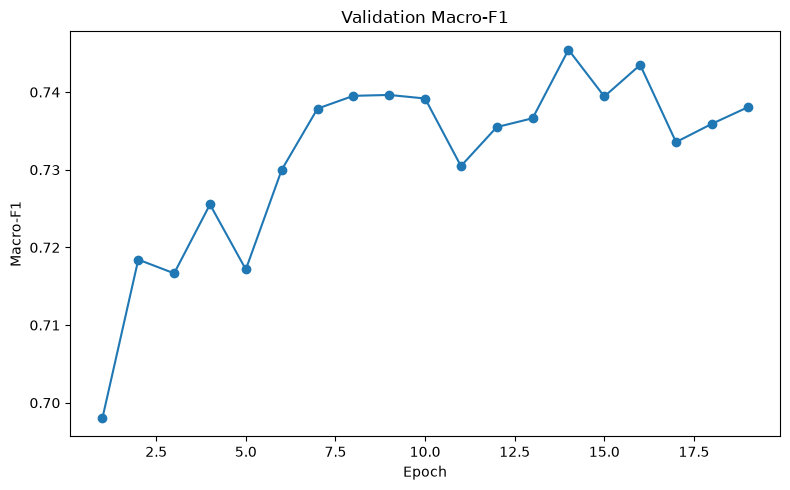

In [116]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs_ran,
    history["val_f1"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("Validation Macro-F1")

plt.tight_layout()
plt.show()

## Final validation evaluation

In [117]:
(
    final_val_loss,
    final_val_f1,
    y_val_true,
    y_val_pred
) = evaluate_model(
    model,
    val_loader,
    criterion,
    device
)

In [118]:
final_accuracy = accuracy_score(
    y_val_true,
    y_val_pred
)

final_precision = precision_score(
    y_val_true,
    y_val_pred,
    average="macro",
    zero_division=0
)

final_recall = recall_score(
    y_val_true,
    y_val_pred,
    average="macro",
    zero_division=0
)

print(
    f"Accuracy:        {final_accuracy:.4f}"
)

print(
    f"Macro Precision: {final_precision:.4f}"
)

print(
    f"Macro Recall:    {final_recall:.4f}"
)

print(
    f"Macro F1:        {final_val_f1:.4f}"
)

Accuracy:        0.7663
Macro Precision: 0.7635
Macro Recall:    0.7375
Macro F1:        0.7455


## Classification report

In [119]:
target_names = [
    index_to_label[i]
    for i in range(3)
]

print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=target_names,
        digits=4,
        zero_division=0
    )
)

                precision    recall  f1-score   support

BenignPositive     0.7487    0.8930    0.8145      8605
 FalsePositive     0.7060    0.6174    0.6588      4313
  TruePositive     0.8358    0.7020    0.7631      6977

      accuracy                         0.7663     19895
     macro avg     0.7635    0.7375    0.7455     19895
  weighted avg     0.7700    0.7663    0.7627     19895



## Confusion Matrix

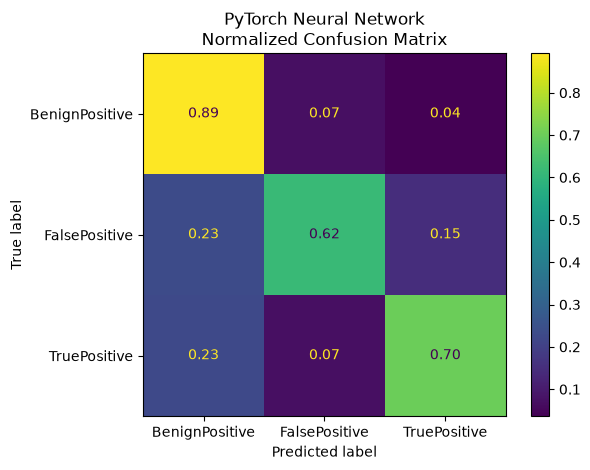

In [120]:
ConfusionMatrixDisplay.from_predictions(
    y_val_true,
    y_val_pred,
    display_labels=target_names,
    normalize="true",
    values_format=".2f"
)

plt.title(
    "PyTorch Neural Network\n"
    "Normalized Confusion Matrix"
)

plt.tight_layout()
plt.show()

## Baseline comparison

In [121]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "PyTorch Embedding Network"
    ],
    "Accuracy": [
        0.7576,
        final_accuracy
    ],
    "Macro Precision": [
        0.7469,
        final_precision
    ],
    "Macro Recall": [
        0.7343,
        final_recall
    ],
    "Macro F1": [
        0.7387,
        final_val_f1
    ]
})

comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.757600,0.746900,0.734300,0.738700
1,PyTorch Embedding Network,0.766273,0.763512,0.737475,0.745453


## Save trained model and preprocessing artifacts

In [122]:
import joblib

MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = (
    MODELS_DIR
    / "pytorch_incident_triage.pt"
)

PREPROCESSOR_PATH = (
    MODELS_DIR
    / "pytorch_preprocessing.joblib"
)

print("Model path:", MODEL_PATH)
print("Preprocessor path:", PREPROCESSOR_PATH)

Model path: c:\Users\zaaaa\OneDrive\Υπολογιστής\New folder\Python Projects\ai-security-incident-triage\models\pytorch_incident_triage.pt
Preprocessor path: c:\Users\zaaaa\OneDrive\Υπολογιστής\New folder\Python Projects\ai-security-incident-triage\models\pytorch_preprocessing.joblib


## Save model weights

In [123]:
torch.save(
    model.state_dict(),
    MODEL_PATH
)

print("Model weights saved.")

Model weights saved.


## Save preprocessing metadata

In [124]:
preprocessing_artifacts = {
    "categorical_features":
        categorical_features,

    "numeric_features":
        numeric_features,

    "category_maps":
        category_maps,

    "category_cardinalities":
        category_cardinalities,

    "embedding_dims":
        embedding_dims,

    "numeric_medians":
        numeric_medians,

    "scaler":
        scaler,

    "label_to_index":
        label_to_index,

    "index_to_label":
        index_to_label,

    "unknown_index":
        UNKNOWN_INDEX,

    "missing_token":
        MISSING_TOKEN
}

In [125]:
joblib.dump(
    preprocessing_artifacts,
    PREPROCESSOR_PATH
)

print(
    "Preprocessing artifacts saved."
)

Preprocessing artifacts saved.


## Verify

In [126]:
print(
    MODEL_PATH.exists(),
    PREPROCESSOR_PATH.exists()
)

True True


### Conclusion

The PyTorch embedding-based neural network achieved a higher validation
Macro-F1 than the Logistic Regression baseline on the same leakage-aware
grouped split.

The neural network improved Macro-F1 from 0.7387 to 0.7455 while using
learned categorical embeddings instead of high-dimensional one-hot
representations.

FalsePositive remained the most challenging class, while the model achieved
the highest recall for BenignPositive and the highest precision for
TruePositive.